# Sentinel-2 Level-2A: read surface reflectance at Harvard Forest

**Worked demo.** The Sentinel-2A scene was acquired on June 11, 2023 over Prospect Hill, Massachusetts. It is the optical scene paired with the June 5 field visit in the Harvard Forest LAI lab.

Level-1C contains top-of-atmosphere reflectance. Level-2A applies an atmospheric correction to estimate bottom-of-atmosphere (surface) reflectance. This makes Level-2A useful for comparing vegetation across dates, but clouds, shadows, and differences in illumination still matter. Level-2A also includes a scene classification raster (SCL). It does not include B10, the Level-1C cirrus measurement.

In [1]:
%pip -q install rasterio scikit-image

Note: you may need to restart the kernel to use updated packages.


## Download the sample

Vision hosts a small GeoTIFF crop of each band. The crop keeps the original pixel values, map coordinates, and pixel spacing. The ZIP includes `provenance.json` with the full-scene catalog record and asset URLs.

In [2]:
%%bash
set -e
wget -nv -O sentinel-2-l2a-demo.zip https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-2-l2a-demo.zip
unzip -oq sentinel-2-l2a-demo.zip -d sentinel-2-l2a-demo

2026-11-18 13:00:19 URL:https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-2-l2a-demo.zip

 [118181/118181] -> "sentinel-2-l2a-demo.zip" [1]


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from skimage.segmentation import find_boundaries

## What the bands measure

| Asset | Nominal resolution | What it shows |
|---|---:|---|
| B01 | 60 m | Coastal aerosol: short visible wavelengths sensitive to atmospheric scattering |
| B02 | 10 m | Blue: natural color and shallow-water features |
| B03 | 10 m | Green: the visible reflectance peak of many leaves |
| B04 | 10 m | Red: chlorophyll absorbs strongly here |
| B05 | 20 m | First red-edge band: start of the rise from red absorption to NIR reflectance |
| B06 | 20 m | Second red-edge band: farther up that rise |
| B07 | 20 m | Third red-edge band: near the NIR shoulder |
| B08 | 10 m | Broad near-infrared (NIR): vegetation often reflects strongly here |
| B8A | 20 m | Narrow NIR: samples a narrower range farther into the NIR |
| B09 | 60 m | Water-vapor absorption: primarily used for atmospheric retrieval |
| B11 | 20 m | Shortwave infrared (SWIR 1): sensitive to liquid water in plants and soils |
| B12 | 20 m | SWIR 2: useful for distinguishing moisture, burn scars, and some exposed materials |
| SCL | 20 m here | Integer scene classes, not reflectance; 4 is vegetation and 6 is water |

Rasterio reads the first (and only) band from each 1.2 km GeoTIFF crop. For this particular product, mask nodata first, then convert the stored digital number (DN) with `(DN - 1000) / 10000`. Check the product metadata for the offset and scale when using a different scene or archive.

In [4]:
bands = {
    "B01": "Coastal aerosol", "B02": "Blue", "B03": "Green", "B04": "Red",
    "B05": "Red edge 1", "B06": "Red edge 2", "B07": "Red edge 3", "B08": "Broad NIR",
    "B8A": "Narrow NIR", "B09": "Water vapor", "B11": "SWIR 1", "B12": "SWIR 2",
    "SCL": "Scene classification",
}
images = {}
for band in bands:
    with rasterio.open(f"sentinel-2-l2a-demo/{band}.tif") as src:
        values = src.read(1, masked=True)
        images[band] = values if band == "SCL" else (values.astype("float32") - 1000) / 10000
        print(f"{band:>3}: {values.shape} at {src.res[0]:g} m/pixel")

B01: (20, 20) at 60 m/pixel
B02: (120, 120) at 10 m/pixel
B03: (120, 120) at 10 m/pixel
B04: (120, 120) at 10 m/pixel
B05: (60, 60) at 20 m/pixel
B06: (60, 60) at 20 m/pixel
B07: (60, 60) at 20 m/pixel
B08: (120, 120) at 10 m/pixel
B8A: (60, 60) at 20 m/pixel
B09: (20, 20) at 60 m/pixel
B11: (60, 60) at 20 m/pixel
B12: (60, 60) at 20 m/pixel
SCL: (60, 60) at 20 m/pixel


## Natural color and individual bands

Natural color assigns B04, B03, and B02 to red, green, and blue. The display stretch brightens the image without changing the reflectance arrays. The reflectance panels all use the same display range (0 to 0.5): compare the relatively dark red band with the brighter NIR bands over vegetation. Values outside this range are clipped in the display only.

### Scene classification (SCL): all 12 classes

SCL is an automated classification for screening pixels, not a land-cover map or a reflectance band. The colorbar shows only the codes present in this crop; this table lists every possible code.

| Code | Class | What it means |
|---:|---|---|
| 0 | No data | No valid observation; masked in the plot. |
| 1 | Saturated or defective | The sensor measurement is saturated or otherwise invalid. |
| 2 | Topographic cast shadow | Terrain blocks direct sunlight. Older products called this class “dark features/shadows.” |
| 3 | Cloud shadow | The pixel is in a shadow cast by a cloud. |
| 4 | Vegetation | The algorithm identifies vegetation; the Harvard Forest lab keeps this class. |
| 5 | Non-vegetated | Land classified as non-vegetated, such as bare ground. |
| 6 | Water | The algorithm identifies a water surface. |
| 7 | Unclassified | The algorithm did not assign a more specific class. |
| 8 | Medium-probability cloud | The algorithm flags a possible cloud. |
| 9 | High-probability cloud | The algorithm flags a more likely cloud. |
| 10 | Thin cirrus | The algorithm detects thin, high cloud. |
| 11 | Snow or ice | The algorithm identifies snow or ice. |

See the [Sentinel Hub SCL reference](https://custom-scripts.sentinel-hub.com/custom-scripts/sentinel-2/scene-classification/) for the class definitions.

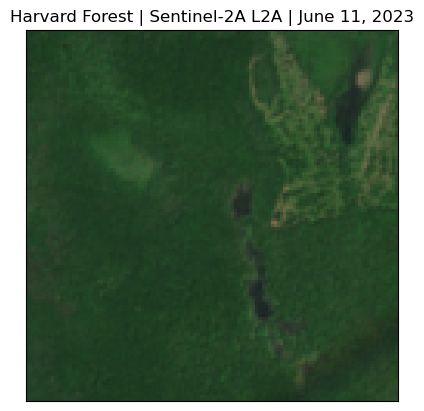

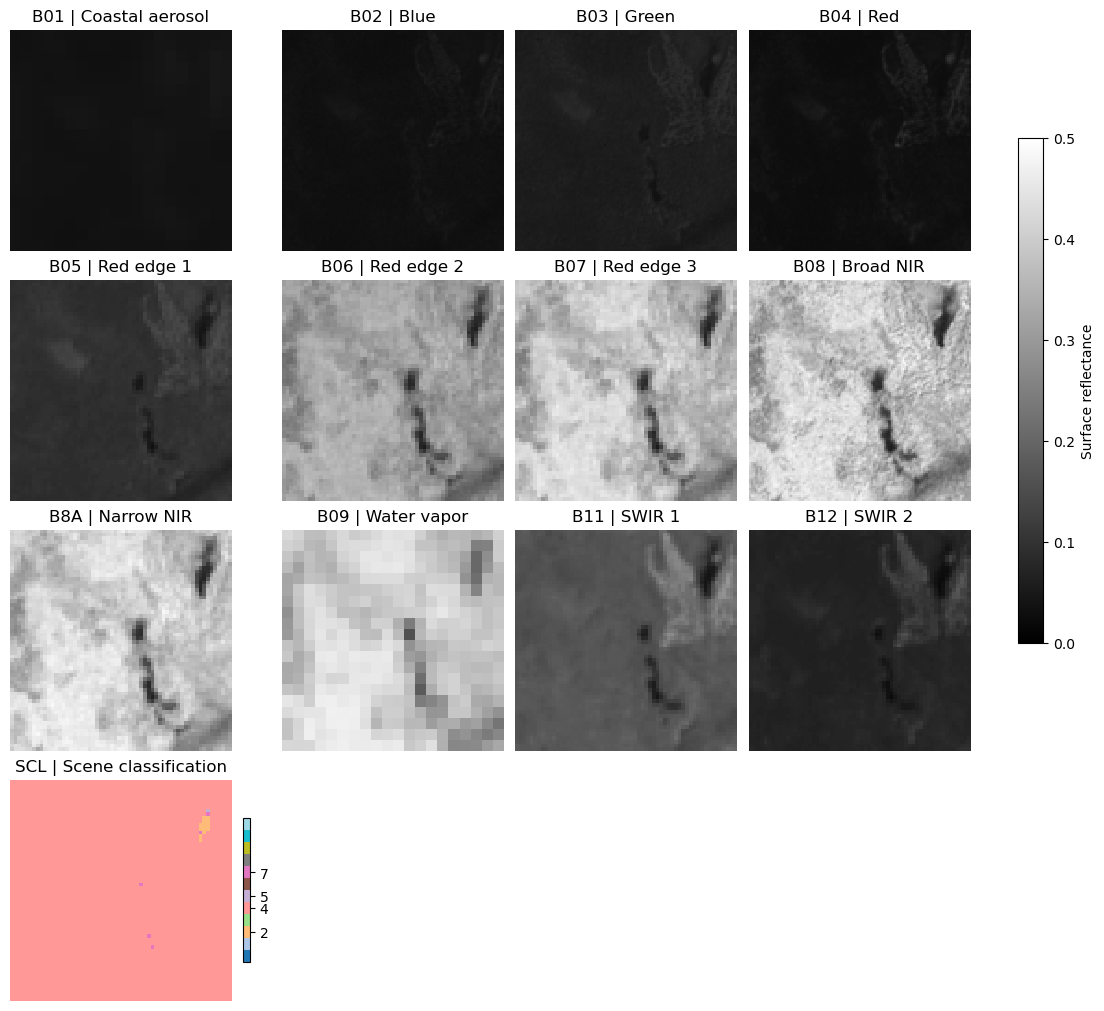

In [5]:
rgb = np.stack([images[key].filled(0) for key in ("B04", "B03", "B02")], axis=-1)
fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
ax.imshow(np.clip(rgb / 0.22, 0, 1))
ax.set(title="Harvard Forest | Sentinel-2A L2A | June 11, 2023", xticks=[], yticks=[])
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(11, 10), layout="constrained")
for ax in axes.flat:
    ax.set_axis_off()
for ax, (band, label) in zip(axes.flat, bands.items()):
    values = images[band]
    if band == "SCL":
        plot = ax.imshow(values, cmap=plt.get_cmap("tab20", 12), vmin=-0.5, vmax=11.5,
                         interpolation="nearest")
        fig.colorbar(plot, ax=ax, shrink=0.65, ticks=np.unique(values.compressed()))
    else:
        reflectance = ax.imshow(values, cmap="gray", vmin=0, vmax=0.5, interpolation="nearest")
    ax.set_title(f"{band} | {label}")
fig.colorbar(reflectance, ax=list(axes.flat)[:12], shrink=0.7, label="Surface reflectance")
plt.show()

## Overlay class boundaries on natural color

`find_boundaries` marks where neighboring SCL labels differ. Yellow pixels
show those transitions, not a particular class. The RGB and SCL crops
cover the same rectangle, but SCL pixels are twice as wide. The overlay
keeps the categorical edges sharp rather than interpolating them.

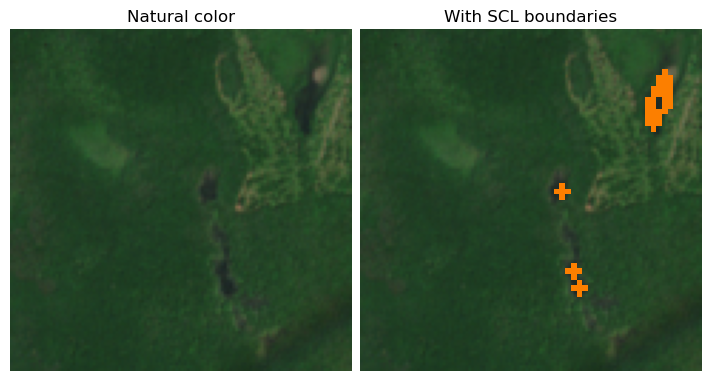

In [6]:
edges = find_boundaries(images["SCL"].filled(0), mode="thick")
fig, axes = plt.subplots(1, 2, figsize=(7, 4), layout="constrained")
for ax, title in zip(axes, ("Natural color", "With SCL boundaries")):
    ax.imshow(np.clip(rgb / 0.22, 0, 1), extent=(0, 1200, 0, 1200))
    ax.set_title(title)
    ax.set_axis_off()
axes[1].imshow(np.ma.masked_where(~edges, edges), extent=(0, 1200, 0, 1200),
               cmap="Wistia", vmin=0, vmax=1, interpolation="nearest")
plt.show()

## Where to get more imagery

In [Copernicus Browser](https://browser.dataspace.copernicus.eu/), sign in with a free account, search for your site, select **Sentinel-2 L2A**, set a date range and a cloud-cover filter, then open a result. Use **Download product** for the original files and metadata, or the analytical image download for a small area and selected bands. For the exact scene above, see the catalog record in `provenance.json`. When an archive gives you a direct or signed asset URL, `wget -O band.tif 'ASSET_URL'` saves it without Python. Signed URLs expire; copy a fresh one if needed.

Source: [Sentinel-2 L2A on Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a) and the [Copernicus Sentinel-2 product guide](https://sentiwiki.copernicus.eu/web/s2-products).
Contains modified Copernicus Sentinel data (2023).